In [1]:
import utils
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm import tqdm

# PARAMETRI

In [3]:
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.001
SEED = 42


DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


# DATASET

TRAIN SET shape: torch.Size([60000, 28, 28])
TEST SET shape:  torch.Size([10000, 28, 28])


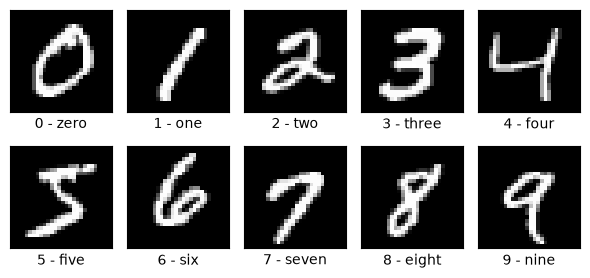

In [4]:
from datasets.datasets import load_MNIST
train_dataset, test_dataset, train_loader, test_loader = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(train_dataset.classes)):
    idx = (train_dataset.targets == c).nonzero()[0].item()   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(train_dataset.classes[label])

plt.tight_layout()
plt.show()

In [5]:
from torch.utils.data import Subset, DataLoader

idx = torch.randperm(len(train_dataset))[:500]
train_loader = DataLoader(Subset(train_dataset, idx), batch_size=BATCH_SIZE, shuffle=True)

# MODELLO SENZA LAYER NORMALIZATION

In [6]:
torch.manual_seed(SEED)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28,  64),
    nn.ReLU(),
    nn.Linear( 64,  16),
    nn.ReLU(),
    nn.Linear( 16, 10),
    # nn.Softmax(dim=1)
)

model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.999), eps=1e-7)

model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=16, bias=True)
  (4): ReLU()
  (5): Linear(in_features=16, out_features=10, bias=True)
)

100%|██████████| 50/50 [01:27<00:00,  1.75s/it]


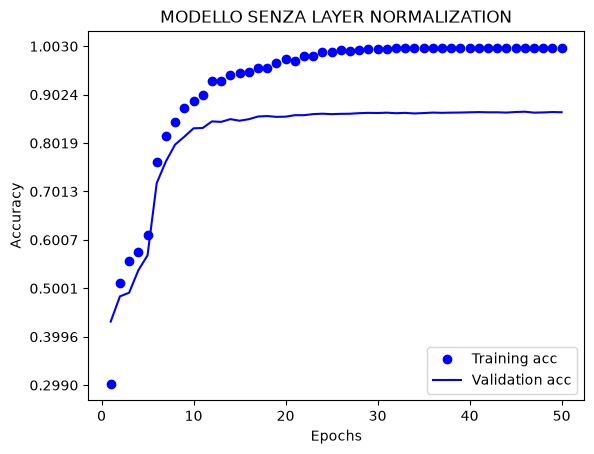

In [7]:
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
n_train = len(train_loader.dataset)
n_test = len(test_loader.dataset)

for epoch in tqdm(range(EPOCHS)):

    model.train()
    train_loss = torch.zeros((), device=DEVICE)
    train_correct = torch.zeros((), device=DEVICE)

    for train_inputs, train_labels in train_loader:

        optimizer.zero_grad()

        train_inputs = train_inputs.to(DEVICE)
        train_labels = train_labels.to(DEVICE)

        outputs = model(train_inputs)
        loss = criterion(outputs, train_labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.detach()*len(train_labels)
        train_correct += (outputs.argmax(dim=1) == train_labels).sum()

    model.eval()
    with torch.no_grad():
        val_loss = torch.zeros((), device=DEVICE)
        val_correct = torch.zeros((), device=DEVICE)

        for val_inputs, val_labels in test_loader:

            val_inputs = val_inputs.to(DEVICE)
            val_labels = val_labels.to(DEVICE)

            val_outputs = model(val_inputs)
            val_loss += criterion(val_outputs, val_labels)*len(val_labels)
            val_correct += (val_outputs.argmax(dim=1) == val_labels).sum()

    history["loss"].append(train_loss.item() / n_train)
    history["accuracy"].append(train_correct.item() / n_train)
    history["val_loss"].append(val_loss.item() / n_test)
    history["val_accuracy"].append(val_correct.item() / n_test)

utils.hist_plot(history, "MODELLO SENZA LAYER NORMALIZATION")

# MODELLO CON LAYER NORMALIZATION

$$
\operatorname{LayerNorm}(x_i)
=
\gamma_i
\frac{x_i-\mu}{\sqrt{\sigma^2+\epsilon}}
+\beta_i
$$

Dove:

- $x_i$: output del nodo i-esimo del layer.
- $\mu$: media degli output dei nodi del layer.
- $\sigma^2$: varianza degli output dei nodi del layer.
- $\epsilon$: piccolo termine positivo per garantire la stabilità numerica.
- $\gamma_i$: parametro di scala (learnable).
- $\beta_i$: parametro di traslazione (learnable).

La media e la varianza sono calcolate indipendentemente per ogni esempio del batch.

In [8]:
torch.manual_seed(SEED)

model_laynorm = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28,  64),
    nn.LayerNorm(64),
    nn.ReLU(),
    nn.Linear(64,  16),
    nn.LayerNorm(16),
    nn.ReLU(),
    nn.Linear(16, 10),
    # nn.Softmax(dim=1)
)

model_laynorm.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer_laynorm = torch.optim.AdamW(model_laynorm.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.999), eps=1e-7)

model_laynorm

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=64, bias=True)
  (2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=16, bias=True)
  (5): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (6): ReLU()
  (7): Linear(in_features=16, out_features=10, bias=True)
)

100%|██████████| 50/50 [01:22<00:00,  1.65s/it]


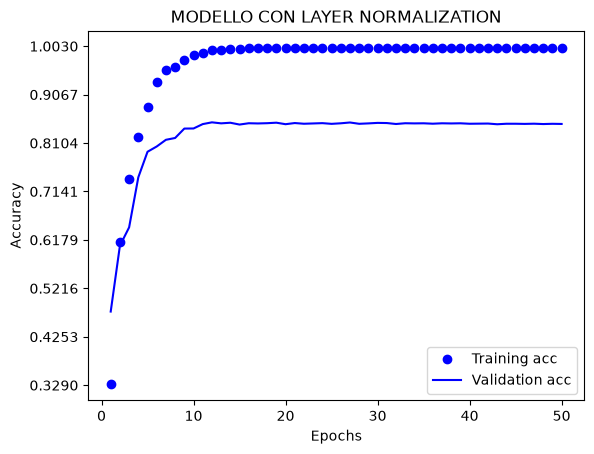

In [9]:
history_laynorm = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
n_train = len(train_loader.dataset)
n_test = len(test_loader.dataset)

for epoch in tqdm(range(EPOCHS)):

    model_laynorm.train()
    train_loss = torch.zeros((), device=DEVICE)
    train_correct = torch.zeros((), device=DEVICE)

    for train_inputs, train_labels in train_loader:

        optimizer_laynorm.zero_grad()

        train_inputs = train_inputs.to(DEVICE)
        train_labels = train_labels.to(DEVICE)

        outputs = model_laynorm(train_inputs)
        loss = criterion(outputs, train_labels)
        loss.backward()
        optimizer_laynorm.step()
        train_loss += loss.detach()*len(train_labels)
        train_correct += (outputs.argmax(dim=1) == train_labels).sum()

    model_laynorm.eval()
    with torch.no_grad():
        val_loss = torch.zeros((), device=DEVICE)
        val_correct = torch.zeros((), device=DEVICE)

        for val_inputs, val_labels in test_loader:

            val_inputs = val_inputs.to(DEVICE)
            val_labels = val_labels.to(DEVICE)

            val_outputs = model_laynorm(val_inputs)
            val_loss += criterion(val_outputs, val_labels)*len(val_labels)
            val_correct += (val_outputs.argmax(dim=1) == val_labels).sum()

    history_laynorm["loss"].append(train_loss.item() / n_train)
    history_laynorm["accuracy"].append(train_correct.item() / n_train)
    history_laynorm["val_loss"].append(val_loss.item() / n_test)
    history_laynorm["val_accuracy"].append(val_correct.item() / n_test)

utils.hist_plot(history_laynorm, "MODELLO CON LAYER NORMALIZATION")

# CONFRONTO

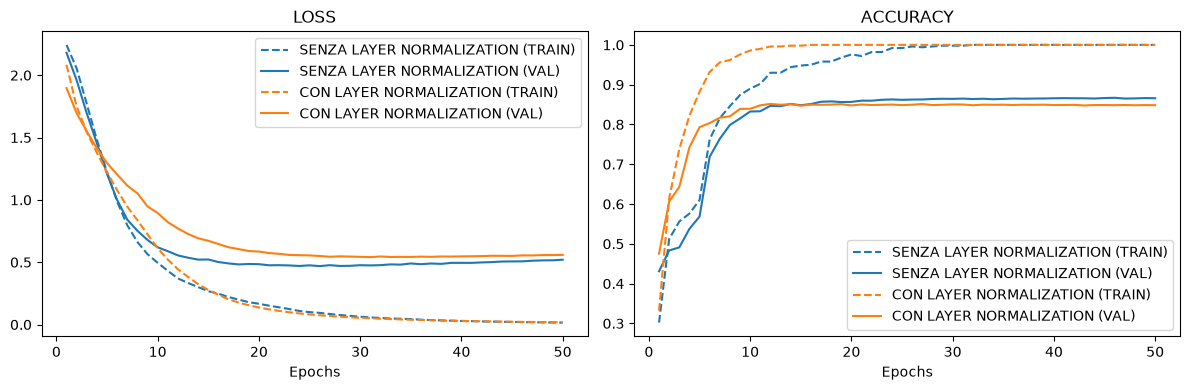

SENZA LAYER NORMALIZATION | TRAIN loss: 0.0157  acc: 1.0000 | VAL loss: 0.5201  acc: 0.8659 | MIN VAL loss: 0.4688 (epoch 26)
CON LAYER NORMALIZATION | TRAIN loss: 0.0184  acc: 1.0000 | VAL loss: 0.5589  acc: 0.8484 | MIN VAL loss: 0.5410 (epoch 31)


In [10]:
results = [(history, "SENZA LAYER NORMALIZATION", "tab:blue"), (history_laynorm, "CON LAYER NORMALIZATION", "tab:orange")]
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))
for k, metric in enumerate(["loss", "accuracy"]):
    plt.subplot(1, 2, k + 1)
    for hist, label, color in results:
        plt.plot(epochs, hist[metric], "--", color=color, label=f"{label} (TRAIN)")
        plt.plot(epochs, hist["val_" + metric], "-", color=color, label=f"{label} (VAL)")
    plt.title(metric.upper())
    plt.xlabel("Epochs")
    plt.legend()
plt.tight_layout()
plt.show()

for hist, label, _ in results:
    best = min(range(EPOCHS), key=lambda e: hist["val_loss"][e])
    print(f"{label:<17} | TRAIN loss: {hist['loss'][-1]:.4f}  acc: {hist['accuracy'][-1]:.4f}"
          f" | VAL loss: {hist['val_loss'][-1]:.4f}  acc: {hist['val_accuracy'][-1]:.4f}"
          f" | MIN VAL loss: {hist['val_loss'][best]:.4f} (epoch {best + 1})")